<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A07_%D0%93%D0%BE%D1%80%D0%B0%D0%A4%D0%86%D0%A24_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

Гора Р.В ФІТ4-9

---

https://colab.research.google.com/drive/1ZeZwGQTaLDBJfFLDC3tAFcnFnU_GLRUg?usp=sharing

---



### 1. Імпорт бібліотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [4]:
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data (1).csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [5]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape

print("Розмір датасету:", df.shape)
display(df.head())
df.info()

Розмір датасету: (2338, 14)


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()

print("Кількість пропусків по стовпцях:\n", df.isnull().sum())
print("\nКількість дублікатів:", df.duplicated().sum())

Кількість пропусків по стовпцях:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [7]:
# TODO: виведіть описову статистику
# Підказка: describe()

df.describe()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
_Напишіть тут, чи є пропуски, дублікати та які особливості даних помітили._

---
Датасет містить 2338 записів та 14 стовпців (13 числових ознак типу float64 і цільову змінну Cured типу int64). Пропущені значення та повні дублікати рядків повністю відсутні. Усі ознаки мають схожий порядок величин (від 1.0 до ~45.0), що свідчить про високу якість і чистоту початкових даних.


### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)

X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (1870, 13), X_test: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [9]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train

print(y_train.value_counts())
print("\nЧастки класів:\n", y_train.value_counts(normalize=True).round(4))

Cured
0    946
1    924
Name: count, dtype: int64

Частки класів:
 Cured
0    0.5059
1    0.4941
Name: proportion, dtype: float64


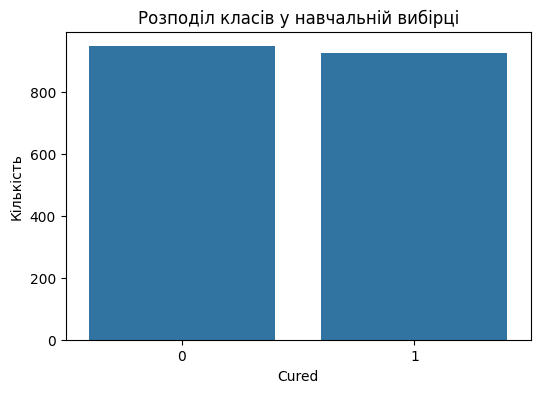

In [10]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)

plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Розподіл класів у навчальній вибірці')
plt.xlabel('Cured')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

---

Класи збалансовані майже ідеально: клас 0 становить 946 записів (50.59%), а клас 1 — 924 записи (49.41%). За такого балансу метрика Accuracy є репрезентативною і не зміщується на користь мажоритарного класу, як це буває при сильному дисбалансі.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

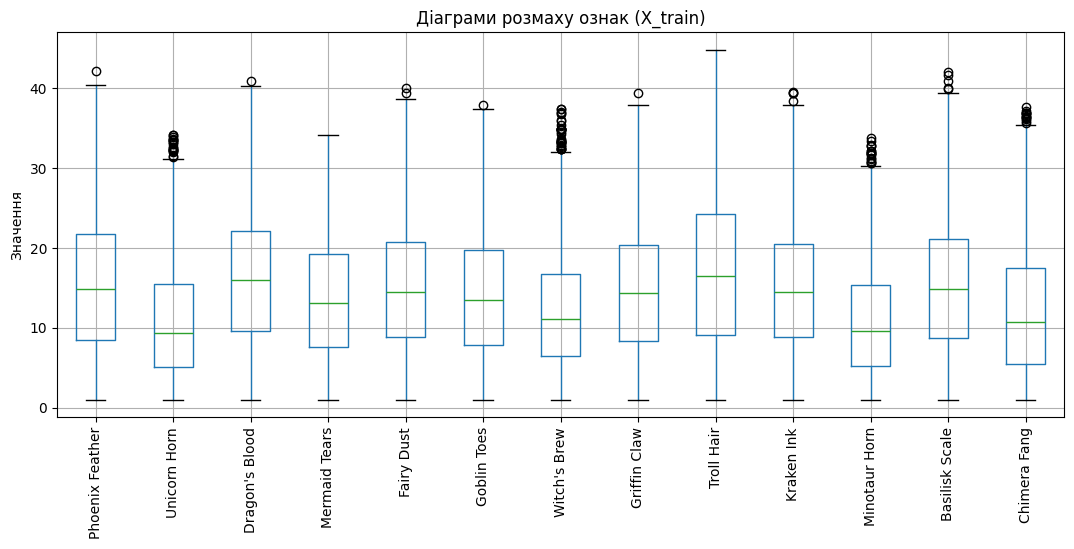

In [11]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)

X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху ознак (X_train)')
plt.ylabel('Значення')
plt.show()

In [12]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням

q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

outliers_count = ((X_train < (q1 - 1.5 * iqr)) | (X_train > (q3 + 1.5 * iqr))).sum()
outliers_count = outliers_count.sort_values(ascending=False)
print("Кількість потенційних викидів за правилом 1.5 IQR:\n", outliers_count)

Кількість потенційних викидів за правилом 1.5 IQR:
 Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

---

Найбільше потенційних викидів зафіксовано в ознаках Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) та Chimera Fang (13). Без додаткової перевірки не варто видаляти всі такі рядки, оскільки в нелінійних або правосторонньо скошених розподілах значення за межами 1.5 * IQR можуть бути не помилками вимірювання, а реальними рідкісними комбінаціями інгредієнтів, важливими для класифікації.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

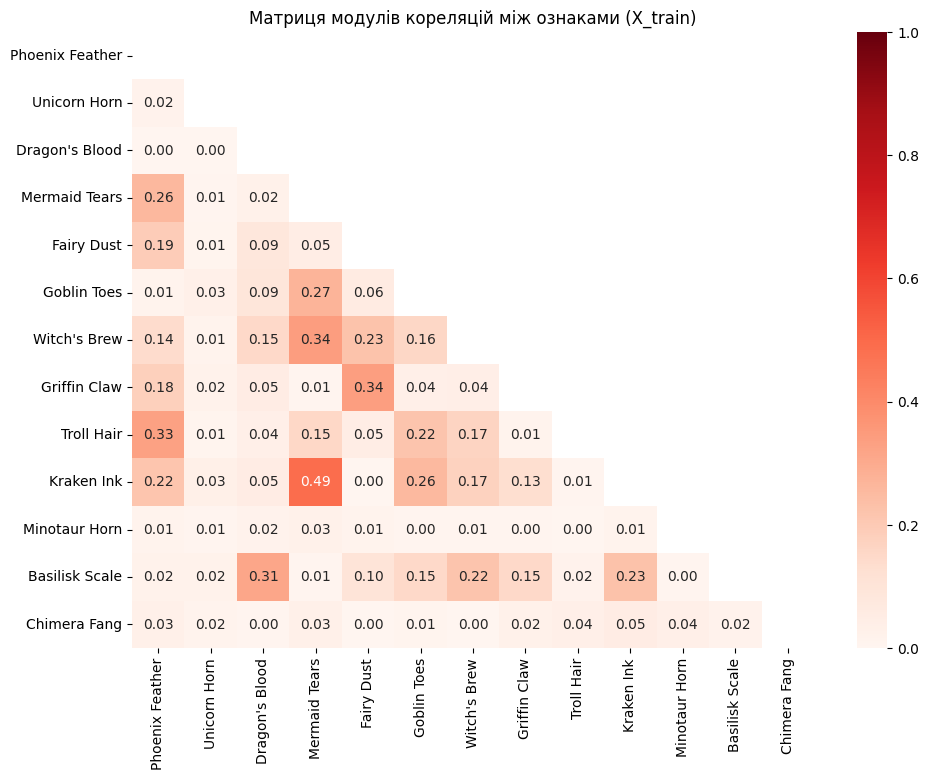

In [13]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1

mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Матриця модулів кореляцій між ознаками (X_train)')
plt.show()

In [14]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
corr_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured')
print("Кореляція ознак із Cured (за спаданням модуля):\n")
print(corr_target.reindex(corr_target.abs().sort_values(ascending=False).index).round(4))

Кореляція ознак із Cured (за спаданням модуля):

Troll Hair         0.4888
Witch's Brew       0.2470
Goblin Toes        0.0526
Chimera Fang       0.0473
Basilisk Scale    -0.0423
Kraken Ink        -0.0266
Minotaur Horn      0.0219
Phoenix Feather    0.0205
Fairy Dust         0.0142
Dragon's Blood     0.0101
Griffin Claw      -0.0059
Unicorn Horn       0.0042
Mermaid Tears      0.0024
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

---
Найсильніша парна кореляція серед ознак спостерігається між Mermaid Tears та Kraken Ink (r = 0.49), а також між Witch's Brew та Mermaid Tears (r = 0.34) і Fairy Dust та Griffin Claw (r = 0.34) — критичної мультиколінеарності (> 0.8) немає. Із цільовою змінною Cured найсильніший лінійний зв'язок мають Troll Hair (r = 0.4888) та Witch's Brew (r = 0.2470).


### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [17]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [18]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

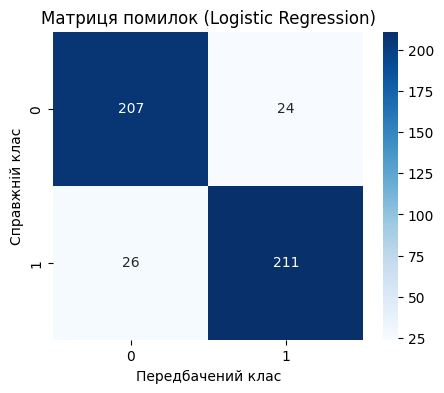

In [19]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)

conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.title('Матриця помилок (Logistic Regression)')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()

In [20]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))

results_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
}, index=y_test.index)

results_df.sample(10, random_state=42)

,Actual,Predicted
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

---
На тестовій вибірці (468 об'єктів) модель правильно класифікувала 207 об'єктів класу 0 та 211 класу 1. Помилки розподілені майже симетрично: 24 хибнопозитивні (FP) та 26 хибнонегативних (FN) прогнозів (загальна точність Accuracy = 0.8932). Однієї метрики Accuracy зазвичай недостатньо, оскільки вона не показує співвідношення між хибними тривогами (Precision) та пропущеними випадками (Recall), що критично у задачах лікування/діагностики.


### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [21]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 500, 1000]
}

param_dist = {
    'C': np.logspace(-3, 3, 20),
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 300, 500, 1000]
}

In [22]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid = GridSearchCV(LogisticRegression(), param_grid, cv=3, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

print("GridSearchCV найкращі параметри:", grid.best_params_)
print(f"GridSearchCV найкращий CV score: {grid.best_score_:.4f}")

GridSearchCV найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
GridSearchCV найкращий CV score: 0.8674


In [23]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(
    LogisticRegression(), param_dist, n_iter=20, cv=3, scoring='accuracy', random_state=42
)
random_search.fit(X_train_scaled, y_train)

print("RandomizedSearchCV найкращі параметри:", random_search.best_params_)
print(f"RandomizedSearchCV найкращий CV score: {random_search.best_score_:.4f}")

RandomizedSearchCV найкращі параметри: {'solver': 'liblinear', 'max_iter': 300, 'C': np.float64(26.366508987303554)}
RandomizedSearchCV найкращий CV score: 0.8674


In [24]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report

best_model = grid.best_estimator_ if grid.best_score_ >= random_search.best_score_ else random_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)

print(f"Test Accuracy після підбору: {accuracy_score(y_test, y_pred_best):.4f}\n")
print("Classification Report:\n", classification_report(y_test, y_pred_best))

Test Accuracy після підбору: 0.8932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

---
GridSearchCV обрав {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}, а RandomizedSearchCV — {'C': 26.37, 'max_iter': 300, 'solver': 'liblinear'} (обидва методи дали однаковий CV-результат 0.8674). На тестовій вибірці метрики залишилися на рівні базової моделі (Accuracy = 0.8932, F1 = 0.8941), оскільки стандартна регуляризація (C=1) уже була близькою до оптимальної для цієї лінійної роздільної поверхні.


### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [25]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель

svc_model = SVC()
dt_model = DecisionTreeClassifier(random_state=42)

svc_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train_scaled, y_train)

models = {
    'Logistic Regression': best_model,
    'SVC (SVM)': svc_model,
    'Decision Tree': dt_model
}

comparison_data = []
for name, clf in models.items():
    preds = clf.predict(X_test_scaled)
    comparison_data.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'F1-score': round(f1_score(y_test, preds), 4)
    })

comparison_df = pd.DataFrame(comparison_data).sort_values(by='F1-score', ascending=False)
display(comparison_df)

best_overall = comparison_df.iloc[0]['Model']
print(f"Найкраща модель за метриками Accuracy та F1-score: {best_overall}")

,Model,Accuracy,F1-score
1,SVC (SVM),0.9594,0.9600
0,Logistic Regression,0.8932,0.8941
2,Decision Tree,0.8654,0.8657


Найкраща модель за метриками Accuracy та F1-score: SVC (SVM)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
_Впишіть відповідь тут._


---
Особливості даних: Датасет містить 2338 записів і 13 числових ознак без пропусків та дублікатів; цільова змінна Cured збалансована майже порівну (~50.6% класу 0 та ~49.4% класу 1).

---

Викиди та кореляції: Найбільше статистичних
викидів виявлено в ознаках Witch's Brew (33) та Unicorn Horn (20). Мультиколінеарність між ознаками відсутня (максимальна кореляція 0.49 між Mermaid Tears та Kraken Ink), а найбільший вплив на цільову змінну мають Troll Hair (r = 0.49) та Witch's Brew (r = 0.25).

---


Якість базової логістичної регресії: Модель показала високу базову точність на тестовій вибірці — Accuracy = 0.8932 та F1-score = 0.8941 (24 хибнопозитивні та 26 хибнонегативних помилок).

---


Вплив підбору гіперпараметрів: Пошук через GridSearchCV та RandomizedSearchCV визначив оптимальне значення C = 10 (lbfgs), проте якість на тестовій вибірці залишилася незмінною (0.8932), що вказує на межу можливостей лінійного класифікатора для цих даних.

---


Найкраща модель: Найвищу якість продемонстрував метод опорних векторів SVC (Accuracy = 0.9594, F1-score = 0.9600), суттєво випередивши логістичну регресію (0.8932) та дерево рішень (0.8654). Це пояснюється тим, що ядро RBF у SVC ефективно вловлює нелінійні залежності між магічними інгредієнтами у багатовимірному просторі ознак.


---


---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.